# Phase 3: Building the Model for Scam Text Classifier

In [1]:
# Imports
import html
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import hstack, csr_matrix

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

In [2]:
# Load and clean the data (same cleaning as the Phase 2 notebook)
def load_data(path):
    df = pd.read_csv(path)
    df["LABEL"] = df["LABEL"].str.strip().str.lower()
    df["TEXT"] = df["TEXT"].str.replace("&lt;#&gt;", " ", regex=False).str.strip().apply(html.unescape)
    for c in ["URL", "EMAIL", "PHONE"]:
        df[c] = df[c].str.lower().eq("yes")
    return df

df = load_data("../data/Dataset_5971.csv")
print("Raw rows:", len(df))

df = df.drop_duplicates().reset_index(drop=True)
print("After removing duplicates:", len(df))

Raw rows: 5971
After removing duplicates: 5876


In [3]:
# Target: ham = 0, scam (spam + smishing) = 1
df["scam"] = (df["LABEL"] != "ham").astype(int)

counts = df["scam"].value_counts()
print(counts)
print("Share of scams:", round(counts[1] / len(df) * 100, 1), "%")

scam
0    4834
1    1042
Name: count, dtype: int64
Share of scams: 17.7 %


In [4]:
# Split into training (80%) and test (20%) sets
# stratify keeps the same ham/scam mix in both sets
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["scam"])

print("Training messages:", len(train_df), "| scam share:", round(train_df["scam"].mean() * 100, 1), "%")
print("Test messages:", len(test_df), "| scam share:", round(test_df["scam"].mean() * 100, 1), "%")

Training messages: 4700 | scam share: 17.7 %
Test messages: 1176 | scam share: 17.8 %


Models:

In [5]:
# Model A: TF-IDF words + Naive Bayes (baseline)
tfidf = TfidfVectorizer(lowercase=True, stop_words="english", min_df=2, max_df=0.9)
X_train_words = tfidf.fit_transform(train_df["TEXT"])   # learn vocabulary from training only
X_test_words  = tfidf.transform(test_df["TEXT"])        # same vocabulary for test
y_train, y_test = train_df["scam"], test_df["scam"]

print("Number of word features:", X_train_words.shape[1])

nb = MultinomialNB()
nb.fit(X_train_words, y_train)
nb_pred = nb.predict(X_test_words)

print(classification_report(y_test, nb_pred, target_names=["ham", "scam"], digits=3))

Number of word features: 3557
              precision    recall  f1-score   support

         ham      0.973     0.998     0.985       967
        scam      0.989     0.871     0.926       209

    accuracy                          0.975      1176
   macro avg      0.981     0.934     0.956      1176
weighted avg      0.976     0.975     0.975      1176



In [6]:
# Model B (part 1): Phase 2 text signals as features
# Phase 2 text signals as features (one row per message)
# Model B (part 1): Phase 2 text signals as features (function lives in src/scam_features.py)
import sys
sys.path.append("..")
from src.scamfeatures import signal_features

S_train = signal_features(train_df["TEXT"])
S_test  = signal_features(test_df["TEXT"])
S_train.groupby(y_train.values).mean().round(2)

,word_count,digits,has_phone,has_shortcode,has_url,has_currency,caps_pct,exclaim,call_to_action,sentiment
0,14.04,0.32,0.00,0.00,0.00,0.00,5.73,0.18,0.10,0.17
1,23.00,15.05,0.58,0.44,0.22,0.27,11.00,0.59,0.77,0.45


In [7]:
# Model B (part 2): scale signals, combine with TF-IDF words, train logistic regression
from sklearn.preprocessing import StandardScaler

# Put the signals on the same scale (fit on training only)
scaler = StandardScaler()
S_train_scaled = scaler.fit_transform(S_train)
S_test_scaled  = scaler.transform(S_test)

# Words + signals side by side
X_train_B = hstack([X_train_words, csr_matrix(S_train_scaled)]).tocsr()
X_test_B  = hstack([X_test_words,  csr_matrix(S_test_scaled)]).tocsr()

# Model B: logistic regression
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_B, y_train)
lr_pred = logreg.predict(X_test_B)

print(classification_report(y_test, lr_pred, target_names=["ham", "scam"], digits=3))

              precision    recall  f1-score   support

         ham      0.979     0.996     0.987       967
        scam      0.979     0.900     0.938       209

    accuracy                          0.979      1176
   macro avg      0.979     0.948     0.962      1176
weighted avg      0.979     0.979     0.978      1176



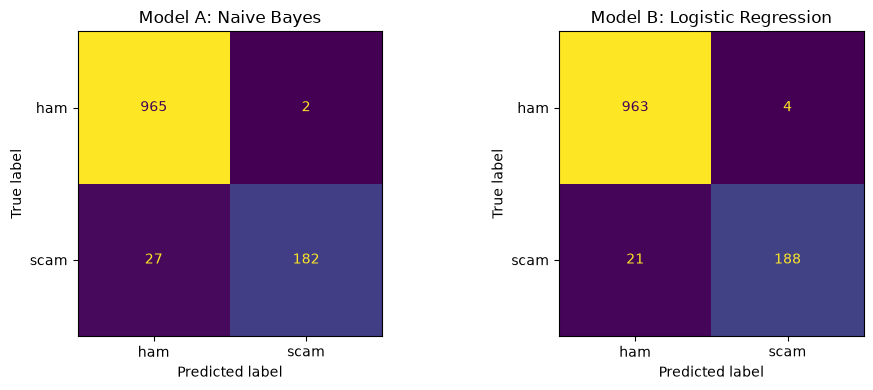

In [8]:
# Confusion matrices: where each model is right and wrong
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, nb_pred, display_labels=["ham", "scam"], ax=axes[0], colorbar=False)
axes[0].set_title("Model A: Naive Bayes")
ConfusionMatrixDisplay.from_predictions(y_test, lr_pred, display_labels=["ham", "scam"], ax=axes[1], colorbar=False)
axes[1].set_title("Model B: Logistic Regression")
plt.tight_layout()
plt.show()

In [9]:
# Check: retrain Model B WITHOUT the phone-number feature
keep = [c for c in S_train.columns if c != "has_phone"]

scaler_np = StandardScaler()
X_train_np = hstack([X_train_words, csr_matrix(scaler_np.fit_transform(S_train[keep]))]).tocsr()
X_test_np  = hstack([X_test_words,  csr_matrix(scaler_np.transform(S_test[keep]))]).tocsr()

logreg_np = LogisticRegression(max_iter=1000).fit(X_train_np, y_train)
print(classification_report(y_test, logreg_np.predict(X_test_np), target_names=["ham", "scam"], digits=3))

              precision    recall  f1-score   support

         ham      0.982     0.995     0.988       967
        scam      0.974     0.914     0.943       209

    accuracy                          0.980      1176
   macro avg      0.978     0.954     0.966      1176
weighted avg      0.980     0.980     0.980      1176



In [10]:
# Step 7: Which features push a message toward "scam" (Model B coefficients)
feature_names = list(tfidf.get_feature_names_out()) + list(S_train.columns)
coefs = pd.Series(logreg.coef_[0], index=feature_names)

print("Phase 2 signals (positive = more likely scam):")
print(coefs[list(S_train.columns)].sort_values(ascending=False).round(2))

print("\nTop 15 scam words:")
print(coefs.drop(S_train.columns).sort_values(ascending=False).head(15).round(2))

print("\nTop 10 ham (safe) words:")
print(coefs.drop(S_train.columns).sort_values().head(10).round(2))

Phase 2 signals (positive = more likely scam):
digits            2.05
has_url           0.96
has_phone         0.94
call_to_action    0.69
has_shortcode     0.63
has_currency      0.46
sentiment         0.26
word_count        0.22
caps_pct          0.11
exclaim           0.10
dtype: float64

Top 15 scam words:
uk          1.66
reply       1.63
mobile      1.33
service     1.32
apple       1.14
stop        1.11
http        1.06
content     1.00
ringtone    1.00
latest      0.99
free        0.98
arsenal     0.95
order       0.94
won         0.92
new         0.91
dtype: float64

Top 10 ham (safe) words:
fullonsms   -1.26
send        -0.95
com         -0.80
got         -0.79
ok          -0.79
added       -0.72
ring        -0.71
ll          -0.62
come        -0.61
later       -0.60
dtype: float64


In [11]:
# Step 8: Enter any message and get the chance it's a scam (uses Model B)
def scam_test(message):
    words = tfidf.transform([message])
    signals = csr_matrix(scaler.transform(signal_features([message])))
    X = hstack([words, signals]).tocsr()
    prob = logreg.predict_proba(X)[0, 1]
    print(f'"{message}"\n→ {prob * 100:.1f}% chance this is a scam\n')
    return prob

In [12]:
scam_test("Hey, are we still meeting for lunch at noon?")
scam_test("URGENT! You have won a £1000 prize. Call 09061701461 now to claim. T&C apply")
scam_test("Your package could not be delivered. Update your address at usps-redelivery.com")
scam_test("Your verification code is 482913. Do not share it with anyone.")

"Hey, are we still meeting for lunch at noon?"
→ 0.5% chance this is a scam

"URGENT! You have won a £1000 prize. Call 09061701461 now to claim. T&C apply"
→ 100.0% chance this is a scam

"Your package could not be delivered. Update your address at usps-redelivery.com"
→ 54.8% chance this is a scam

"Your verification code is 482913. Do not share it with anyone."
→ 30.2% chance this is a scam



np.float64(0.30239032440580366)

In [13]:
# Save the trained Model B so other notebooks can use it without retraining
import os, joblib
os.makedirs("../models", exist_ok=True)
joblib.dump({"tfidf": tfidf, "scaler": scaler, "model": logreg}, "../models/scam_model.joblib")
print("Saved model to models/scam_model.joblib")

Saved model to models/scam_model.joblib
